In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from tqdm import tqdm

In [2]:
def get_run_names(str_list):
    run_names = []
    for i,string in enumerate(str_list):
        run_names.append(string.split("_")[0]+'_'+string.split("_")[1])
    return run_names

In [3]:
def normalize(DA):
    start_date = '1950-06-30T12:00:00.000000000'
    end_date = '2000-06-30T12:00:00.000000000'
    mean = DA.loc[start_date:end_date].mean('time')
    std_dev = DA.loc[start_date:end_date].std('time')
    normalized_DA = (DA-mean)/std_dev
    return normalized_DA

In [4]:
def rollmean(DA,n_months=3*10):
    running_mean = DA.rolling(time=n_months,center='True').mean('time')#.fillna(0)
    return running_mean

In [5]:
def select_reference_period(arr):
    start_date = '1931-06-30T12:00:00.000000000'
    end_date = '2014-07-31T12:00:00.000000000'
    return arr.loc[start_date:end_date]

def compute_freq_distribution(freq_list,n_months=3*10):
    freqs = []
    for elmnt in tqdm(freq_list):
        freqs.append(np.amax(rollmean(elmnt)))
    freqs_np_arr = np.array(freqs)
    return freqs_np_arr

def compute_ERA5_max_freq(freq,n_months=3*10):
    freq =  rollmean(freq).fillna(0)
    freq_np_array = np.array(freq)
    return freq,np.amax(freq_np_array),np.argmax(freq_np_array)

In [6]:
'''
Importing the datasets
'''
import os
# Path to the dataset directory
dataset_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical/

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_all = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'GHA' in f and 'all' in f# and 'CanESM' in f 
]

dataset_file_list_all = sorted(dataset_file_list_all)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_retrograding = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'GHA' in f and 'retrograding' in f# and 'CanESM' in f 
]

dataset_file_list_retrograding = sorted(dataset_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
dataset_file_list_upstream = [
    f for f in os.listdir(dataset_path) 
    if os.path.isfile(os.path.join(dataset_path, f)) and 'GHA' in f and 'upstream' in f# and 'CanESM' in f 
]

dataset_file_list_upstream = sorted(dataset_file_list_upstream)

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/historical


In [7]:
#import data
DAs_all = []
for name in dataset_file_list_all:
    DAs_all.append(normalize(xr.open_dataset(name)['GHA monthly blocking frequency']))
#import data
DAs_retrograding = []
for name in dataset_file_list_retrograding:
    DAs_retrograding.append(normalize(xr.open_dataset(name)['GHA monthly blocking frequency']))
#import data
DAs_upstream = []
for name in dataset_file_list_upstream:
    DAs_upstream.append(normalize(xr.open_dataset(name)['GHA monthly blocking frequency']))

In [8]:
#compute ensemble average
combined_all = xr.concat(DAs_all, dim='ensemble')
average_all = combined_all.mean(dim='ensemble')
combined_retrograding = xr.concat(DAs_retrograding, dim='ensemble')
average_retrograding = combined_retrograding.mean(dim='ensemble')
combined_upstream = xr.concat(DAs_upstream, dim='ensemble')
average_upstream = combined_upstream.mean(dim='ensemble')

In [9]:
#import ERA5 frequency
ERA5_all = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_all_GHA_historical.nc')['GHA monthly blocking frequency'])
ERA5_retrograding = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_retrograding_GHA_historical.nc')['GHA monthly blocking frequency'])
ERA5_upstream = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_upstream_GHA_historical.nc')['GHA monthly blocking frequency'])

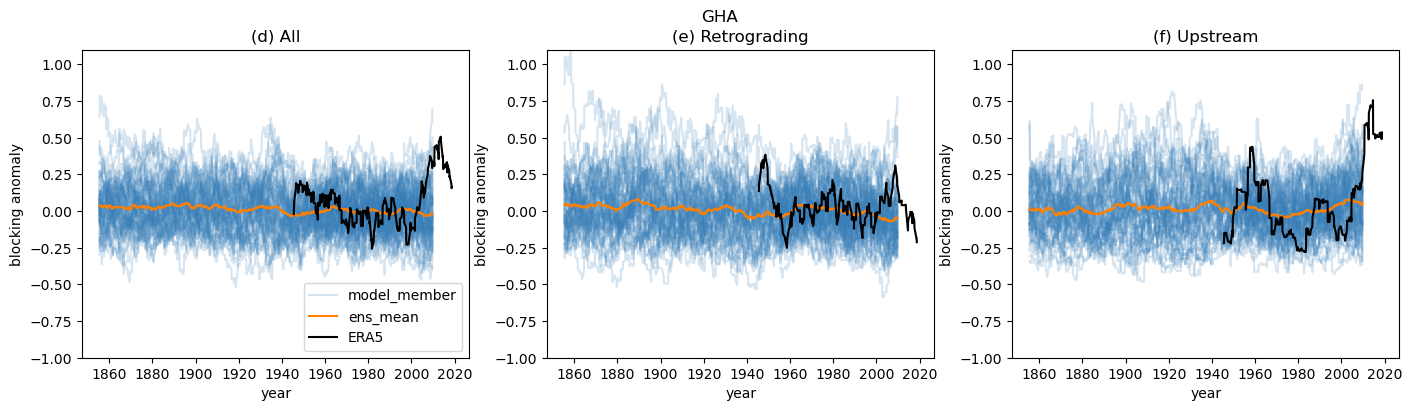

In [10]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17, 4))
plt.suptitle('GHA')
colors = ['#377eb8', '#ff7f00', 'black']

axes[0].set_title('(d) All')
for i,element in enumerate(DAs_all):
    if i == 0:
        axes[0].plot(element['time'],rollmean(element),color=colors[0],alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],rollmean(element),color=colors[0],alpha=0.2)
axes[0].plot(average_all['time'],rollmean(average_all),color = colors[1],label='ens_mean')
axes[0].plot(ERA5_all['time'],rollmean(ERA5_all),color = colors[2],label='ERA5')
axes[0].legend()
axes[0].set_ylabel('blocking anomaly')
axes[0].set_xlabel('year')
axes[0].set_ylim(-1,+1.1)

axes[1].set_title('(e) Retrograding')
for element in DAs_retrograding:
    axes[1].plot(element['time'], rollmean(element),color=colors[0],alpha=0.2)
axes[1].plot(average_retrograding['time'], rollmean(average_retrograding),color = colors[1])
axes[1].plot(ERA5_retrograding['time'], rollmean(ERA5_retrograding),color = colors[2])
axes[1].set_ylim(-1,+1.1)
axes[1].set_ylabel('blocking anomaly')
axes[1].set_xlabel('year')

axes[2].set_title('(f) Upstream')
for element in DAs_upstream:
    axes[2].plot(element['time'], rollmean(element),color=colors[0],alpha=0.2)
axes[2].plot(average_upstream['time'], rollmean(average_upstream),color = colors[1])
axes[2].plot(ERA5_upstream['time'], rollmean(ERA5_upstream),color = colors[2])
axes[2].set_ylim(-1,+1.1)
axes[2].set_ylabel('blocking anomaly')
axes[2].set_xlabel('year')

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/CMIP6_hist_analysis/PLOTS/GHA_frequency_trend_analysis.png',dpi=300)

### FREQ VALUE ANALYSIS

In [11]:
n_months = 3*10

#apply to CMIP models -all
#compute distr
freq_np_arr_all = compute_freq_distribution(DAs_all)
#compute max ERA5 trend
freq_ERA5_all,max_freq_all,idx_all = compute_ERA5_max_freq(ERA5_all)

#apply to CMIP models -retrograding
#compute distr
freq_np_arr_retrograding = compute_freq_distribution(DAs_retrograding)
#compute max ERA5 trend
freq_ERA5_retrograding,max_freq_retrograding,idx_retrograding = compute_ERA5_max_freq(ERA5_retrograding)

#apply to CMIP models -upstream
#compute distr
freq_np_arr_upstream = compute_freq_distribution(DAs_upstream)
#compute max ERA5 trend
freq_ERA5_upstream,max_freq_upstream,idx_upstream = compute_ERA5_max_freq(ERA5_upstream)

100%|██████████████████████████████████████████████████████████████████████| 70/70 [00:00<00:00, 302.88it/s]


In [12]:
print(freq_ERA5_all['time'][idx_all])

<xarray.DataArray 'time' ()> Size: 8B
array('2013-06-30T06:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 2013-06-30T06:00:00


0.8646908502207022 0.7557772546219803


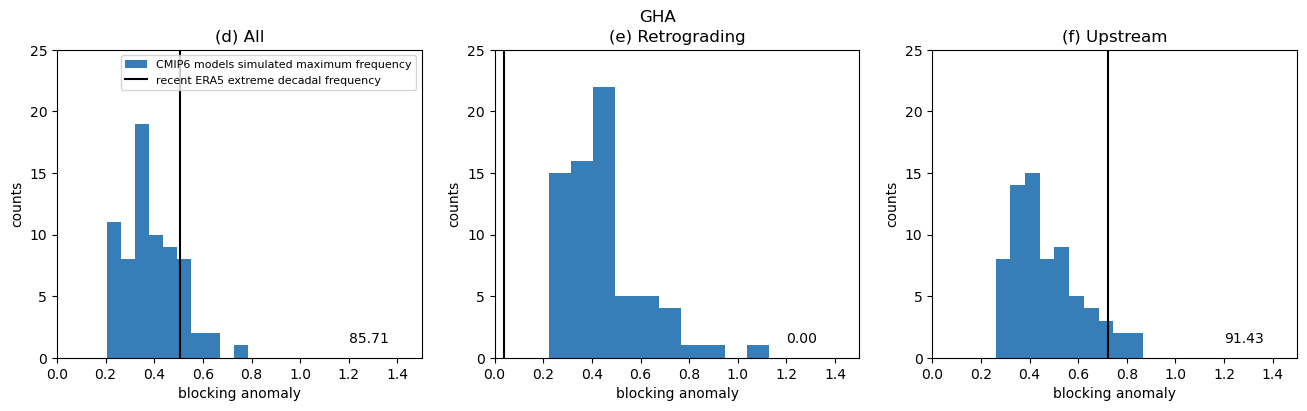

In [13]:
from scipy.stats import percentileofscore

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
plt.suptitle('GHA')

axes[0].set_title('(d) All')
axes[0].hist(freq_np_arr_all,bins=10,label='CMIP6 models simulated maximum frequency',color=colors[0])
axes[0].axvline(x=max_freq_all, color=colors[2],label='recent ERA5 extreme decadal frequency')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].legend(fontsize=8)
percentile = percentileofscore(freq_np_arr_all,max_freq_all)
axes[0].text(1.2,1.2,f'{percentile:.2f}')
axes[0].set_ylim(0,25)
axes[0].set_xlim(0,1.5)
axes[0].set_xlabel('blocking anomaly')
axes[0].set_ylabel('counts')

axes[1].set_title('(e) Retrograding')
axes[1].hist(freq_np_arr_retrograding,color=colors[0])
axes[1].axvline(x=freq_ERA5_retrograding[idx_all], color=colors[2],label='recent extreme decadal frequency')#, linestyle='STYLE', linewidth=WIDTH)
percentile = percentileofscore(freq_np_arr_retrograding,freq_ERA5_retrograding[idx_all])
axes[1].text(1.2,1.2,f'{percentile:.2f}')
axes[1].set_ylim(0,25)
axes[1].set_xlim(0,1.5)
axes[1].set_xlabel('blocking anomaly')
axes[1].set_ylabel('counts')

axes[2].set_title('(f) Upstream')
axes[2].hist(freq_np_arr_upstream,color=colors[0])
axes[2].axvline(x=freq_ERA5_upstream[idx_all], color=colors[2],label='recent extreme decadal frequency')#, linestyle='STYLE', linewidth=WIDTH)
percentile = percentileofscore(freq_np_arr_upstream,freq_ERA5_upstream[idx_all])
print(np.amax(freq_np_arr_upstream),np.amax(freq_ERA5_upstream).values)
axes[2].text(1.2,1.2,f'{percentile:.2f}')
axes[2].set_ylim(0,25)
axes[2].set_xlim(0,1.5)
axes[2].set_xlabel('blocking anomaly')
axes[2].set_ylabel('counts')

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/CMIP6_hist_analysis/PLOTS/GHA_frequency_distr_analysis.png',dpi=300)